In [16]:
# ============================================================
# CELL 1: IMPORT LIBRARIES
# ============================================================

import os
import joblib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not installed. It will be skipped.")

In [17]:
# ============================================================
# CELL 2: LOAD COMBINED CSV
# ============================================================

DATA_PATH = "../data/imd_rainfall_2021_2025.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

display(df.head())
print(df.columns.tolist())

Dataset loaded successfully.
Shape: (1826, 2)


,time,rainfall_mm
0,2021-01-01,0.591625
1,2021-01-02,0.020424
2,2021-01-03,0.584557
3,2021-01-04,1.516260
4,2021-01-05,1.730590


['time', 'rainfall_mm']


In [30]:
print(df["rainfall_mm"].describe())

print("\nMaximum rainfall:")
print(df["rainfall_mm"].max())

print("\nTop 20 rainfall values:")
print(
    df["rainfall_mm"]
    .sort_values(ascending=False)
    .head(20)
)

print("Values above 1 mm:", (df["rainfall_mm"] > 1).sum())
print("Values above 5 mm:", (df["rainfall_mm"] > 5).sum())
print("Values above 10 mm:", (df["rainfall_mm"] > 10).sum())
print("Values above 25 mm:", (df["rainfall_mm"] > 25).sum())
print("Values above 50 mm:", (df["rainfall_mm"] > 50).sum())

count    1826.000000
mean        3.311487
std         3.632610
min         0.000000
25%         0.400466
50%         1.746915
75%         5.546140
max        16.109636
Name: rainfall_mm, dtype: float64

Maximum rainfall:
16.109636

Top 20 rainfall values:
591     16.109636
1310    15.829672
1667    15.458866
1309    15.341625
557     15.305854
558     15.218073
554     15.184423
1277    15.150078
1308    15.071161
919     14.591745
937     14.364572
1334    14.099147
559     14.003091
203     13.811258
1282    13.758269
199     13.748994
202     13.722033
555     13.708205
932     13.586073
1668    13.526695
Name: rainfall_mm, dtype: float64
Values above 1 mm: 1102
Values above 5 mm: 518
Values above 10 mm: 131
Values above 25 mm: 0
Values above 50 mm: 0


In [18]:
# ============================================================
# CELL 3: CLEAN DATA
# ============================================================

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Convert time column
df["time"] = pd.to_datetime(df["time"])

# Sort chronologically
df = df.sort_values("time").reset_index(drop=True)

# Remove duplicate dates
df = df.drop_duplicates(subset=["time"])

# Ensure rainfall is numeric
df["rainfall_mm"] = pd.to_numeric(
    df["rainfall_mm"],
    errors="coerce"
)

# Remove invalid rainfall values
df = df.dropna(subset=["rainfall_mm"])

# Negative rainfall is invalid
df = df[df["rainfall_mm"] >= 0]

df = df.reset_index(drop=True)

print("\nCleaned dataset:")
print(df.shape)

display(df.head())

Missing values:
time           0
rainfall_mm    0
dtype: int64

Cleaned dataset:
(1826, 2)


,time,rainfall_mm
0,2021-01-01,0.591625
1,2021-01-02,0.020424
2,2021-01-03,0.584557
3,2021-01-04,1.516260
4,2021-01-05,1.730590


In [19]:
# ============================================================
# CELL 4: DATASET INFORMATION
# ============================================================

print("Start date:", df["time"].min())
print("End date:", df["time"].max())

print("\nRainfall statistics:")
display(df["rainfall_mm"].describe())

print("\nRainfall events:")
print("> 0 mm:", (df["rainfall_mm"] > 0).sum())
print("> 25 mm:", (df["rainfall_mm"] > 25).sum())
print("> 50 mm:", (df["rainfall_mm"] > 50).sum())
print("> 100 mm:", (df["rainfall_mm"] > 100).sum())

Start date: 2021-01-01 00:00:00
End date: 2025-12-31 00:00:00

Rainfall statistics:


count    1826.000000
mean        3.311487
std         3.632610
min         0.000000
25%         0.400466
50%         1.746915
75%         5.546140
max        16.109636
Name: rainfall_mm, dtype: float64


Rainfall events:
> 0 mm: 1801
> 25 mm: 0
> 50 mm: 0
> 100 mm: 0


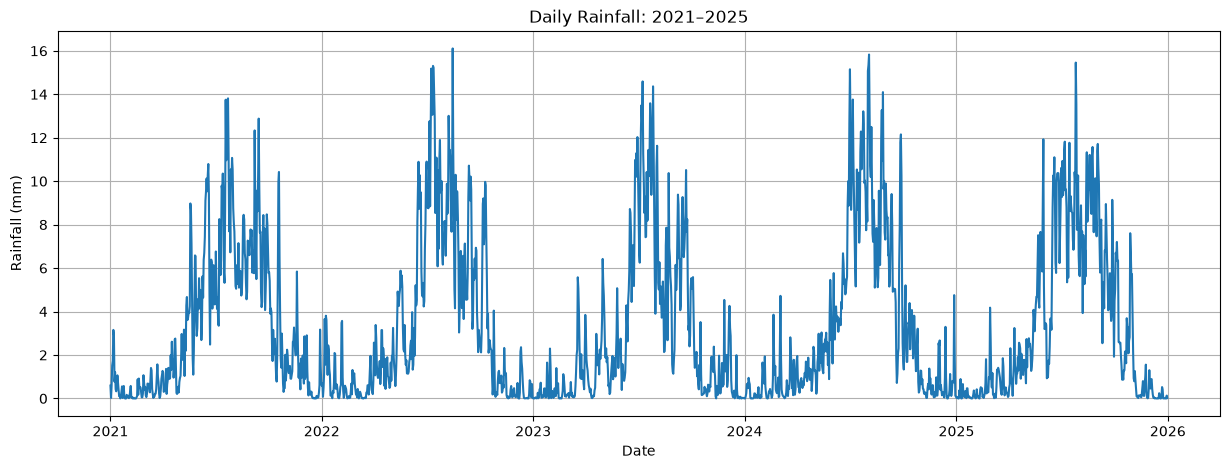

In [20]:
# ============================================================
# CELL 5: VISUALIZE RAINFALL HISTORY
# ============================================================

plt.figure(figsize=(15, 5))

plt.plot(
    df["time"],
    df["rainfall_mm"]
)

plt.title("Daily Rainfall: 2021–2025")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.grid(True)

plt.show()

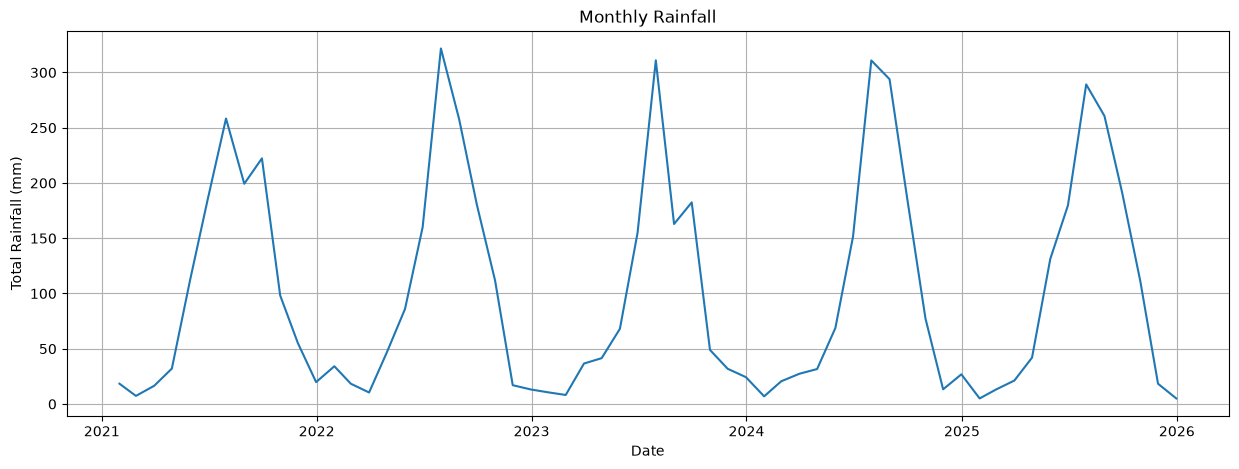

In [21]:
# ============================================================
# CELL 6: MONTHLY RAINFALL ANALYSIS
# ============================================================

monthly_rainfall = (
    df.set_index("time")["rainfall_mm"]
      .resample("ME")
      .sum()
)

plt.figure(figsize=(15, 5))

plt.plot(monthly_rainfall.index, monthly_rainfall.values)

plt.title("Monthly Rainfall")
plt.xlabel("Date")
plt.ylabel("Total Rainfall (mm)")
plt.grid(True)

plt.show()

In [22]:
# ============================================================
# CELL 7: CREATE CALENDAR FEATURES
# ============================================================

df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["day"] = df["time"].dt.day
df["day_of_year"] = df["time"].dt.dayofyear

# Cyclic seasonal features
df["month_sin"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["month"] / 12
)

df["day_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365
)

df["day_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365
)

In [23]:
# ============================================================
# CELL 8: CREATE LAG FEATURES
# ============================================================

# Previous rainfall values
df["rain_lag_1"] = df["rainfall_mm"].shift(1)
df["rain_lag_2"] = df["rainfall_mm"].shift(2)
df["rain_lag_3"] = df["rainfall_mm"].shift(3)
df["rain_lag_7"] = df["rainfall_mm"].shift(7)

# Rolling rainfall totals
df["rain_rolling_3"] = (
    df["rainfall_mm"]
    .rolling(window=3)
    .sum()
)

df["rain_rolling_7"] = (
    df["rainfall_mm"]
    .rolling(window=7)
    .sum()
)

# Rolling average
df["rain_avg_7"] = (
    df["rainfall_mm"]
    .rolling(window=7)
    .mean()
)

# Rolling maximum
df["rain_max_7"] = (
    df["rainfall_mm"]
    .rolling(window=7)
    .max()
)

display(df.head(10))

,time,rainfall_mm,year,month,day,day_of_year,month_sin,month_cos,day_sin,day_cos,rain_lag_1,rain_lag_2,rain_lag_3,rain_lag_7,rain_rolling_3,rain_rolling_7,rain_avg_7,rain_max_7
0,2021-01-01,0.591625,2021,1,1,1,0.5,0.866025,0.017213,0.999852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-02,0.020424,2021,1,2,2,0.5,0.866025,0.034422,0.999407,0.591625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021-01-03,0.584557,2021,1,3,3,0.5,0.866025,0.051620,0.998667,0.020424,0.591625,NaN,NaN,1.196605,NaN,NaN,NaN
3,2021-01-04,1.516260,2021,1,4,4,0.5,0.866025,0.068802,0.997630,0.584557,0.020424,0.591625,NaN,2.121241,NaN,NaN,NaN
4,2021-01-05,1.730590,2021,1,5,5,0.5,0.866025,0.085965,0.996298,1.516260,0.584557,0.020424,NaN,3.831406,NaN,NaN,NaN
5,2021-01-06,3.154650,2021,1,6,6,0.5,0.866025,0.103102,0.994671,1.730590,1.516260,0.584557,NaN,6.401499,NaN,NaN,NaN
6,2021-01-07,2.897433,2021,1,7,7,0.5,0.866025,0.120208,0.992749,3.154650,1.730590,1.516260,NaN,7.782672,10.495537,1.499362,3.15465
7,2021-01-08,0.772913,2021,1,8,8,0.5,0.866025,0.137279,0.990532,2.897433,3.154650,1.730590,0.591625,6.824996,10.676826,1.525261,3.15465
8,2021-01-09,1.203922,2021,1,9,9,0.5,0.866025,0.154309,0.988023,0.772913,2.897433,3.154650,0.020424,4.874268,11.860324,1.694332,3.15465
9,2021-01-10,0.420108,2021,1,10,10,0.5,0.866025,0.171293,0.985220,1.203922,0.772913,2.897433,0.584557,2.396943,11.695876,1.670839,3.15465


In [31]:
# ============================================================
# CELL 9: CREATE TARGET
# ============================================================

THRESHOLD = df["rainfall_mm"].quantile(0.90)

next_day_rain = df["rainfall_mm"].shift(-1)

df["target_heavy_rain"] = np.where(
    next_day_rain.isna(),
    np.nan,
    (next_day_rain >= THRESHOLD).astype(int)
)

print("Threshold:", THRESHOLD, "mm")
print(df["target_heavy_rain"].value_counts(dropna=False))

Threshold: 9.269971 mm
target_heavy_rain
0.0    1642
1.0     183
NaN       1
Name: count, dtype: int64


In [32]:
# ============================================================
# CELL 10: DEFINE FEATURES AND CLEAN FINAL DATASET
# ============================================================

features = [
    "rainfall_mm",

    # Lag features
    "rain_lag_1",
    "rain_lag_2",
    "rain_lag_3",
    "rain_lag_7",

    # Rolling features
    "rain_rolling_3",
    "rain_rolling_7",
    "rain_avg_7",
    "rain_max_7",

    # Seasonal features
    "month",
    "day_of_year",
    "month_sin",
    "month_cos",
    "day_sin",
    "day_cos"
]

df_model = df.dropna(
    subset=features + ["target_heavy_rain"]
).copy()

df_model["target_heavy_rain"] = (
    df_model["target_heavy_rain"]
    .astype(int)
)

print("Final modeling dataset:", df_model.shape)

print("\nClass distribution:")
print(df_model["target_heavy_rain"].value_counts())

print("\nClass percentages:")
print(
    df_model["target_heavy_rain"]
    .value_counts(normalize=True) * 100
)

Final modeling dataset: (1818, 19)

Class distribution:
target_heavy_rain
0    1635
1     183
Name: count, dtype: int64

Class percentages:
target_heavy_rain
0    89.933993
1    10.066007
Name: proportion, dtype: float64


In [34]:
# ============================================================
# CELL 11: CHRONOLOGICAL SPLIT
# ============================================================

train_df = df_model[
    df_model["year"] <= 2023
].copy()

val_df = df_model[
    df_model["year"] == 2024
].copy()

test_df = df_model[
    df_model["year"] == 2025
].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nYears:")
print("Train:", train_df["year"].unique())
print("Validation:", val_df["year"].unique())
print("Test:", test_df["year"].unique())

Training: (1088, 19)
Validation: (366, 19)
Testing: (364, 19)

Years:
Train: [2021 2022 2023]
Validation: [2024]
Test: [2025]


In [35]:
# ============================================================
# CELL 12: PREPARE X AND y
# ============================================================

X_train = train_df[features]
y_train = train_df["target_heavy_rain"]

X_val = val_df[features]
y_val = val_df["target_heavy_rain"]

X_test = test_df[features]
y_test = test_df["target_heavy_rain"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nPositive heavy-rain events:")
print("Train:", y_train.sum())
print("Validation:", y_val.sum())
print("Test:", y_test.sum())

X_train: (1088, 15)
X_val: (366, 15)
X_test: (364, 15)

Positive heavy-rain events:
Train: 99
Validation: 41
Test: 43


In [36]:
# ============================================================
# CELL 13: DEFINE MODELS
# ============================================================

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=3,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

if XGBOOST_AVAILABLE:

    models["XGBoost"] = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )

print("Models to compare:")
for model_name in models:
    print("-", model_name)

Models to compare:
- Logistic Regression
- Random Forest
- Gradient Boosting
- XGBoost


In [37]:
# ============================================================
# CELL 14: TRAIN AND VALIDATE MODELS
# ============================================================

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    # Probability scores for PR-AUC / ROC-AUC
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_val)[:, 1]
    else:
        probabilities = predictions

    # Handle ROC-AUC if validation contains only one class
    try:
        roc_auc = roc_auc_score(y_val, probabilities)
    except ValueError:
        roc_auc = np.nan

    try:
        pr_auc = average_precision_score(y_val, probabilities)
    except ValueError:
        pr_auc = np.nan

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }

    results.append(result)
    trained_models[name] = model

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)


Training Logistic Regression...

Training Random Forest...

Training Gradient Boosting...

Training XGBoost...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.918033,0.579710,0.975610,0.727273,0.976735,0.846911
3,XGBoost,0.934426,0.742857,0.634146,0.684211,0.966304,0.745985
1,Random Forest,0.907104,0.553846,0.878049,0.679245,0.962702,0.727026
2,Gradient Boosting,0.931694,0.750000,0.585366,0.657534,0.966904,0.772433


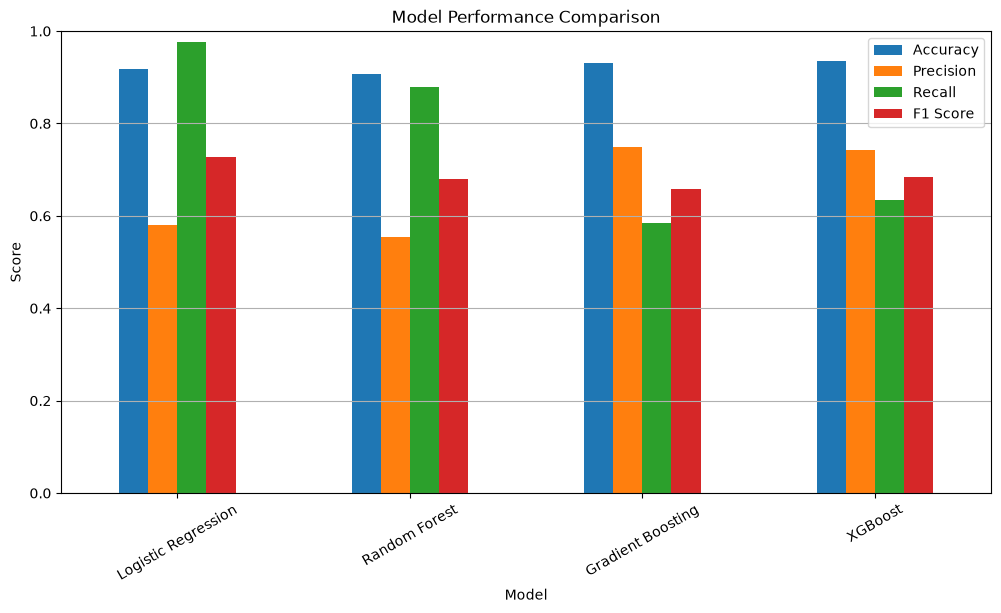

In [38]:
# ============================================================
# CELL 15: COMPARE MODELS VISUALLY
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

In [39]:
# ============================================================
# CELL 16: SELECT BEST MODEL
# ============================================================

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

best_model = trained_models[best_model_name]

print("Best model selected:", best_model_name)

Best model selected: Logistic Regression


In [40]:
# ============================================================
# CELL 17: FINAL TEST EVALUATION
# ============================================================

test_predictions = best_model.predict(X_test)

if hasattr(best_model, "predict_proba"):
    test_probabilities = best_model.predict_proba(X_test)[:, 1]
else:
    test_probabilities = test_predictions

print("FINAL TEST RESULTS")
print("=" * 50)

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Normal Rainfall",
            "Heavy Rainfall"
        ],
        zero_division=0
    )
)

try:
    print(
        "ROC-AUC:",
        roc_auc_score(y_test, test_probabilities)
    )
except ValueError:
    print("ROC-AUC unavailable: only one class present.")

try:
    print(
        "PR-AUC:",
        average_precision_score(y_test, test_probabilities)
    )
except ValueError:
    print("PR-AUC unavailable.")

FINAL TEST RESULTS
                 precision    recall  f1-score   support

Normal Rainfall       0.99      0.88      0.93       321
 Heavy Rainfall       0.51      0.95      0.66        43

       accuracy                           0.88       364
      macro avg       0.75      0.91      0.80       364
   weighted avg       0.94      0.88      0.90       364

ROC-AUC: 0.9539955082228501
PR-AUC: 0.6252063470905141


[[281  40]
 [  2  41]]


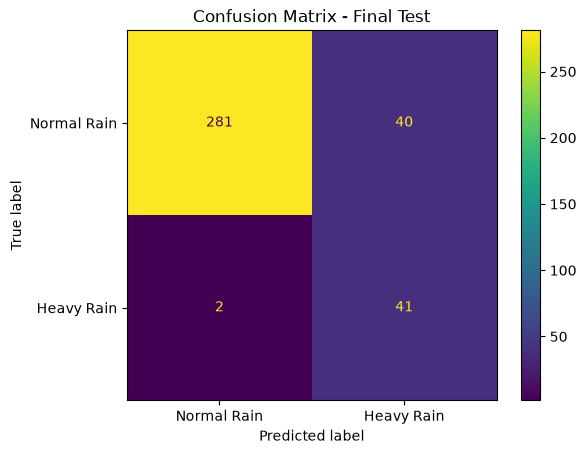

In [41]:
# ============================================================
# CELL 18: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_predictions
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal Rain",
        "Heavy Rain"
    ]
)

disp.plot()

plt.title("Confusion Matrix - Final Test")
plt.show()

In [42]:
# ============================================================
# CELL 19: FEATURE IMPORTANCE
# ============================================================

if hasattr(best_model, "feature_importances_"):

    importance_df = pd.DataFrame({
        "Feature": features,
        "Importance": best_model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    display(importance_df)

    plt.figure(figsize=(10, 6))

    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    plt.xlabel("Importance")
    plt.title(f"Feature Importance - {best_model_name}")

    plt.gca().invert_yaxis()

    plt.show()

else:
    print(
        f"{best_model_name} does not provide tree-based feature importance."
    )

Logistic Regression does not provide tree-based feature importance.


,time,rainfall_mm,target_heavy_rain,predicted_heavy_rain,prediction_probability
1461,2025-01-01,0.027581,0,0,0.000047
1462,2025-01-02,0.056030,0,0,0.000039
1463,2025-01-03,0.049450,0,0,0.000039
1464,2025-01-04,0.000000,0,0,0.000010
1465,2025-01-05,0.001082,0,0,0.000007
1466,2025-01-06,0.375438,0,0,0.000012
1467,2025-01-07,0.074105,0,0,0.000009
1468,2025-01-08,0.891718,0,0,0.000020
1469,2025-01-09,0.006403,0,0,0.000010
1470,2025-01-10,0.000000,0,0,0.000011


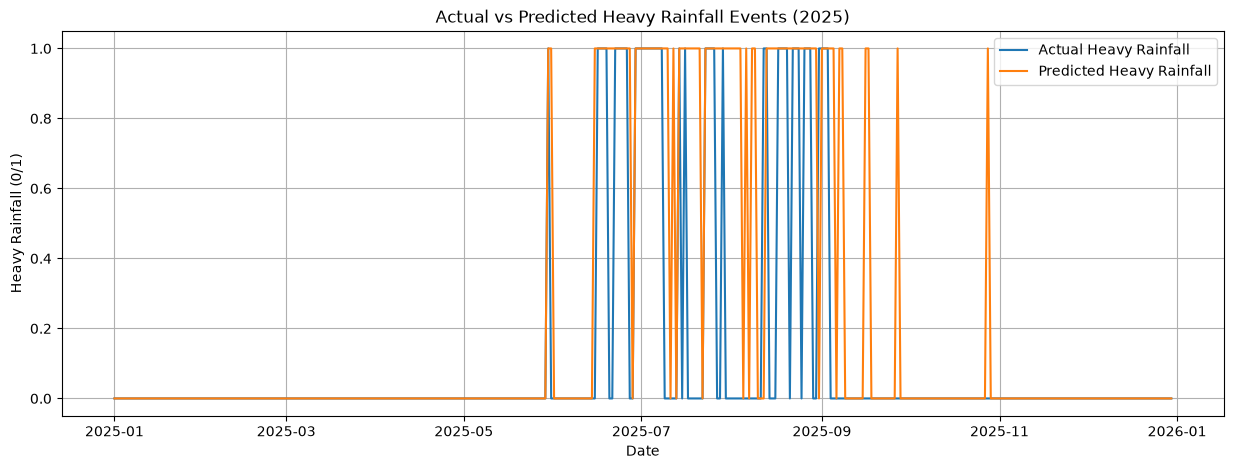

In [43]:
# ============================================================
# CELL 20: ACTUAL VS PREDICTED EVENTS
# ============================================================

comparison_df = test_df[
    ["time", "rainfall_mm", "target_heavy_rain"]
].copy()

comparison_df["predicted_heavy_rain"] = test_predictions
comparison_df["prediction_probability"] = test_probabilities

display(comparison_df.head(20))

plt.figure(figsize=(15, 5))

plt.plot(
    comparison_df["time"],
    comparison_df["target_heavy_rain"],
    label="Actual Heavy Rainfall"
)

plt.plot(
    comparison_df["time"],
    comparison_df["predicted_heavy_rain"],
    label="Predicted Heavy Rainfall"
)

plt.title("Actual vs Predicted Heavy Rainfall Events (2025)")
plt.xlabel("Date")
plt.ylabel("Heavy Rainfall (0/1)")
plt.legend()
plt.grid(True)

plt.show()

In [44]:
# ============================================================
# CELL 21: SAVE MODEL
# ============================================================

MODEL_DIR = "../models"

os.makedirs(MODEL_DIR, exist_ok=True)

model_path = os.path.join(
    MODEL_DIR,
    "best_rainfall_model.pkl"
)

joblib.dump(best_model, model_path)

# Also save feature names and threshold
metadata = {
    "model_name": best_model_name,
    "features": features,
    "threshold_mm": THRESHOLD
}

metadata_path = os.path.join(
    MODEL_DIR,
    "rainfall_model_metadata.pkl"
)

joblib.dump(metadata, metadata_path)

print("Model saved:", model_path)
print("Metadata saved:", metadata_path)

Model saved: ../models\best_rainfall_model.pkl
Metadata saved: ../models\rainfall_model_metadata.pkl


In [45]:
# ============================================================
# CELL 22: SAMPLE PREDICTION
# ============================================================

latest_data = df_model.iloc[[-1]][features]

prediction = best_model.predict(latest_data)[0]

probability = best_model.predict_proba(
    latest_data
)[0][1]

print("Next-day heavy rainfall prediction:")

if prediction == 1:
    print("WARNING: Heavy rainfall predicted.")
else:
    print("No heavy rainfall predicted.")

print(f"Probability: {probability:.2%}")

Next-day heavy rainfall prediction:
No heavy rainfall predicted.
Probability: 0.08%
